# 02 MODELO MATEMÁTICO-FÍSICO PARA MODELAGEM DINÂMICA GLACIAL, ADVECÇÃO, MISI E DATUM VERTICAL

Este caderno desenvolve a teoria matemática e física que governa o escoamento das geleiras do Mar de Amundsen (Thwaites, Pine Island e Smith–Pope–Kohler) e demonstra como os módulos dinâmicos do pacote (`thwaites.glaciology.advection`, `thwaites.validate.velocity`, `thwaites.diagnostics.vulnerability` e `thwaites.corrections.datum`) separam processos cinemáticos de mudanças reais de massa.

---

## 1. Conservação de Massa Integrada na Vertical: Referencial Euleriano vs. Referencial Lagrangiano

Considere uma coluna de gelo de espessura $H(x, y, t) = h(x, y, t) - b(x, y, t)$ (onde $h$ é a cota da superfície e $b$ é a cota da base do gelo) escoando com velocidade horizontal média na coluna $\mathbf{u}(x, y, t) = (u, v)$. Integrando a equação da continuidade tridimensional $\nabla_3 \cdot \mathbf{u}_3 = 0$ da base $z = b$ ao topo $z = h$ sob as condições cinemáticas de contorno na superfície e na base, obtém-se a **equação fundamental da conservação de massa glacial**:

$$\frac{\partial H}{\partial t} + \nabla\cdot(H\mathbf{u}) = \dot{a}_s - \dot{m}_b$$

onde $\dot{a}_s$ é o balanço de massa superficial (acumulação menos ablação, $\text{SMB}$) e $\dot{m}_b$ é a taxa de derretimento basal (positiva para perda de gelo), ambos expressos em metros de gelo equivalente por ano.

### 1.1 Decomposição da Divergência de Fluxo e o Papel da Advecção
Aplicando a identidade vetorial $\nabla\cdot(H\mathbf{u}) = \mathbf{u}\cdot\nabla H + H(\nabla\cdot\mathbf{u})$, temos duas formas matematicamente equivalentes da lei de conservação:

1. **Forma Euleriana (em coordenadas espaciais fixas $(x, y)$):**
   $$\frac{\partial H}{\partial t} = \dot{a}_s - \dot{m}_b - \underbrace{\mathbf{u}\cdot\nabla H}_{\text{advecção de espessura}} - \underbrace{H(\nabla\cdot\mathbf{u})}_{\text{afinamento por estiramento longitudinal/transversal}}$$
   Integrando sobre um domínio fixo $\Omega$ de gelo apoiado (onde $b$ é o leito rochoso fixo, logo $\partial_t H = \partial_t h$):
   $$\frac{dV}{dt} = \iint_\Omega \frac{\partial h}{\partial t}\,dA = \iint_\Omega (\dot{a}_s - \dot{m}_b)\,dA - \oint_{\partial\Omega} H(\mathbf{u}\cdot\mathbf{n})\,ds$$
   **Implicação crucial (`thwaites.glaciology.advection`):** A integral espacial da taxa Euleriana $\partial h / \partial t$ medida pelo ICESat-2 sobre o domínio apoiado $\Omega$ **já é exatamente a variação total de volume $dV/dt$ daquele domínio!** O termo de transporte $\mathbf{u}\cdot\nabla h$ redistribui massa internamente e cruza a fronteira $\partial\Omega$ (a linha de aterramento), mas **nunca deve ser somado novamente ao balanço de massa regional integrado**, sob pena de contar a descarga dinâmica duas vezes.

2. **Forma Lagrangiana (seguindo a parcela material $\frac{d\mathbf{X}}{dt} = \mathbf{u}(\mathbf{X}, t)$):**
   Definindo a derivada material (substantiva) ao longo da trajetória da coluna de gelo:
   $$\frac{DH}{Dt} \equiv \frac{\partial H}{\partial t} + \mathbf{u}\cdot\nabla H$$
   a equação da continuidade simplifica-se para:
   $$\frac{DH}{Dt} + H(\nabla\cdot\mathbf{u}) = \dot{a}_s - \dot{m}_b \quad \Longrightarrow \quad \dot{m}_b = \dot{a}_s - \frac{DH}{Dt} - H(\nabla\cdot\mathbf{u})$$
   **Por que a forma Lagrangiana é superior para mapear derretimento basal em plataformas rápidas (Moholdt et al., 2014; Shean et al., 2019; Adusumilli et al., 2020):**
   Sobre plataformas que escoam a $1\text{--}4\text{ km/ano}$, a superfície possui ondulações topográficas, fendas e canais basais com gradientes locais $|\nabla H| \sim 10^{-2}\text{--}10^{-1}$. Em uma célula fixa Euleriana, a simples passagem dessas ondulações gera $\partial_t H = -\mathbf{u}\cdot\nabla H$ de dezenas de metros por ano, mascarando completamente $\dot{m}_b$. Ao seguir a parcela material ($DH/Dt$), o termo $\mathbf{u}\cdot\nabla H$ é absorvido cinematicamente sem precisar diferenciar numericamente um campo ruidoso de espessura $\nabla H$, restando apenas a divergência da velocidade $H(\nabla\cdot\mathbf{u})$.

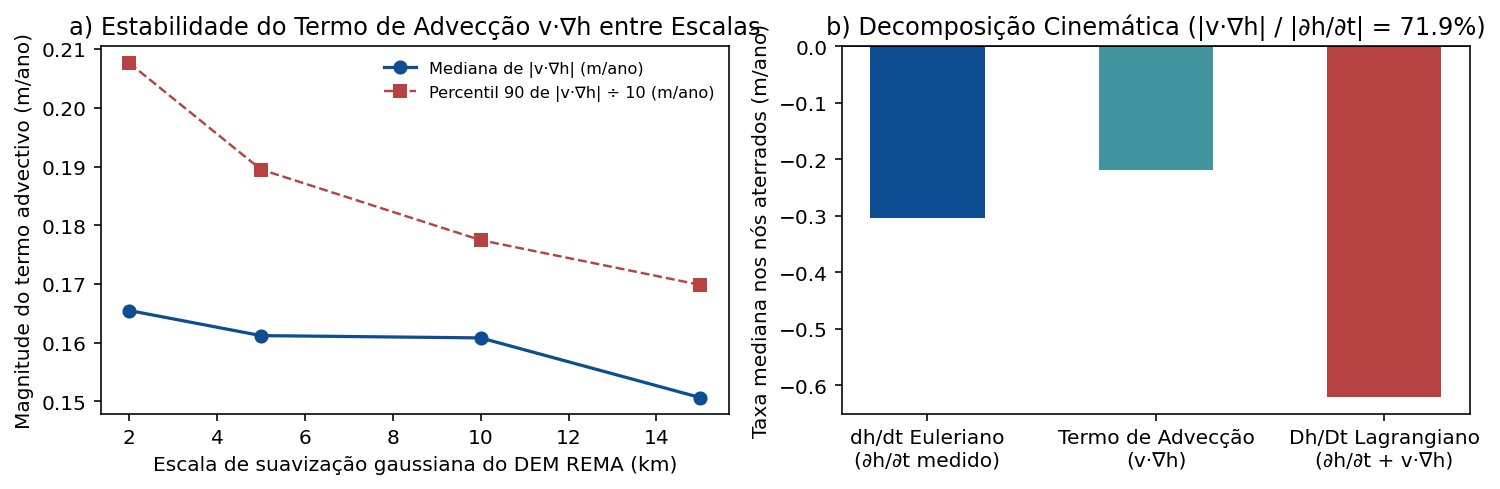

,n_valid,adv_median_m_yr,adv_abs_median_m_yr,adv_p90_abs_m_yr,speed_median_m_yr,slope_median
smooth_km,,,,,,
2.0,11602,-0.1363,0.1655,2.0764,44.0525,0.0051
5.0,11602,-0.1535,0.1612,1.8949,44.0525,0.0045
10.0,11602,-0.1574,0.1608,1.7747,44.0525,0.0045
15.0,11602,-0.1468,0.1507,1.6985,44.0525,0.0044


In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

adv_sum = json.loads((DATA_DIR / "jja_advection_summary.json").read_text(encoding="utf-8"))
adv_sens = pd.read_csv(DATA_DIR / "jja_advection_sensitivity.csv")

fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.5))
ax[0].plot(adv_sens["smooth_km"], adv_sens["adv_abs_median_m_yr"], "o-", color="#0F4D92", lw=1.6, label="Mediana de |v·∇h| (m/ano)")
ax[0].plot(adv_sens["smooth_km"], adv_sens["adv_p90_abs_m_yr"] / 10.0, "s--", color="#B64342", lw=1.2, label="Percentil 90 de |v·∇h| ÷ 10 (m/ano)")
ax[0].set_xlabel("Escala de suavização gaussiana do DEM REMA (km)")
ax[0].set_ylabel("Magnitude do termo advectivo (m/ano)")
ax[0].set_title("a) Estabilidade do Termo de Advecção v·∇h entre Escalas")
ax[0].legend(frameon=False, fontsize=8)

termos = ["dh/dt Euleriano\n(∂h/∂t medido)", "Termo de Advecção\n(v·∇h)", "Dh/Dt Lagrangiano\n(∂h/∂t + v·∇h)"]
vals = [adv_sum["dhdt_eulerian_median"], adv_sum["advection_median"], adv_sum["dhdt_lagrangian_median"]]
ax[1].bar(termos, vals, color=["#0F4D92", "#42949E", "#B64342"], width=0.5)
ax[1].axhline(0, color="k", lw=0.8)
ax[1].set_ylabel("Taxa mediana nos nós aterrados (m/ano)")
ax[1].set_title(f"b) Decomposição Cinemática (|v·∇h| / |∂h/∂t| = {100*adv_sum['abs_advection_over_abs_dhdt']:.1f}%)")
plt.tight_layout()

adv_sens.set_index("smooth_km").round(4)

---
## 2. Mecânica da Instabilidade do Manto de Gelo Marinho (MISI), *Buttressing* e Classificação Dinâmica

### 2.1 Fluxo na Linha de Aterramento e Leito Retrógrado (Weertman, 1974; Schoof, 2007; Gudmundsson, 2013)
Na ausência de contenção lateral ou frontal por uma plataforma flutuante (*unbuttressed marine ice sheet*), a análise assintótica de camada limite de Schoof (2007, *JGR*) mostra que o fluxo de gelo $q_{\text{GL}} = H_{\text{GL}} u_{\text{GL}}$ através da linha de aterramento é uma função fortemente não-linear da espessura na linha de aterramento $H_{\text{GL}}$ e do fator de contenção (*buttressing*) $\Theta \in (0, 1]$ exercido pela plataforma de gelo:

$$q_{\text{GL}} = \left(\frac{A (\rho_i g)^{n+1} (1 - \rho_i/\rho_w)^n}{4^n C}\right)^{\frac{1}{m+1}} \Theta^{\frac{n}{m+1}} H_{\text{GL}}^{\frac{m + n + 3}{m + 1}}$$

onde $A$ e $n \approx 3$ são os parâmetros da lei de fluência de Glen ($\dot{\varepsilon}_{ij} = A \tau_e^{n-1} \tau_{ij}$), $C$ e $m \approx 1/3$ são os parâmetros da lei de atrito basal de Weertman ($\tau_b = C u^m$), dando um expoente superlinear $\gamma = (m+n+3)/(m+1) \approx 19/4 = 4{,}75$. Pela condição de flutuação hidrostática na linha de aterramento, $H_{\text{GL}} = -(\rho_w/\rho_i) b(x_{\text{GL}})$.

Se o leito marinho aprofunda para o interior continental — **declive retrógrado**, definido em `thwaites.diagnostics.vulnerability.along_flow_bed_slope` por:
$$S_{\text{bed, fluxo}} = \frac{\nabla b \cdot \mathbf{u}}{\|\mathbf{u}\|} > 0$$
então qualquer recuo da linha de aterramento para águas mais profundas aumenta $H_{\text{GL}}$, o que eleva a descarga $q_{\text{GL}} \propto H_{\text{GL}}^{4{,}75}$, provocando maior afinamento dinâmico e novo recuo (**MISI**). Quando o derretimento basal afina a plataforma flutuante ou a zona de cisalhamento se fragmenta (Wild et al., 2022), o fator $\Theta$ diminui, acelerando o escoamento a montante mesmo antes que a geometria local mude.

### 2.2 Classificação Dinâmica Conjunta ($\text{dh/dt} \times \|\mathbf{u}\|$) e Precursores Dinâmicos (`thwaites.validate.velocity`)
Cruzar a taxa altimétrica $\text{dh/dt}$ com a velocidade superficial $\|\mathbf{u}\|$ evita o erro clássico de declarar uma região interior como "dinamicamente estável" apenas porque $|\text{dh/dt}|$ é pequeno:
- Nós onde $|\text{dh/dt}| \le 1{,}96\,\sigma_{\text{dh/dt}}$ **mas** $\|\mathbf{u}\| \ge 100\text{ m/ano}$ (`sem_tendencia_mas_fluxo_rapido`, $202$ nós identificados no domínio) constituem possíveis **precursores dinâmicos** (troncos de escoamento rápido onde o afinamento ainda é compensado temporariamente por convergência ou acumulação);
- **Correção obrigatória por autocorrelação espacial (`correlation_with_autocorrelation`):** A correlação de Spearman entre $\text{dh/dt}$ e $\|\mathbf{u}\|$ em $8.656$ nós é $r_s = -0{,}618$. Um teste ingênuo que trate os $8.656$ nós como independentes devolve $p \approx 0$ ("altamente significativo"), mas com o comprimento de correlação conservador $L = 154{,}4\text{ km}$ existem apenas $n_{\text{eff}} = A/(\pi L^2) = 5{,}34$ graus de liberdade espaciais independentes, resultando em $p_{\text{corrigido}} = 0{,}237$ (não significativo globalmente!).

In [2]:
from thwaites.diagnostics.vulnerability import along_flow_bed_slope

dyn_sum = json.loads((DATA_DIR / "jja_dynamics_summary.json").read_text(encoding="utf-8"))

# Demonstração do cálculo de declive retrógrado do leito ao longo do fluxo (along_flow_bed_slope)
x_g = np.linspace(0, 60_000, 61)
y_g = np.linspace(0, 40_000, 41)
XG, YG = np.meshgrid(x_g, y_g)
# Leito que aprofunda para o interior (x crescente = direção para o oceano, b sobe de -1200 m para -500 m)
bed_retro = -1200.0 + 0.012 * XG + 80.0 * np.cos(YG / 8000.0)
vx_sim = np.full_like(XG, 800.0)
vy_sim = np.zeros_like(YG)
s_along = along_flow_bed_slope(bed_retro, x_g, y_g, vx_sim, vy_sim)

cls_df = pd.DataFrame([
    {"Classe Dinâmica Conjunta (dh/dt × velocidade)": k, "Número de Nós": v, "Fração (%)": 100 * v / dyn_sum["n_nodes"]}
    for k, v in dyn_sum["class_counts"].items()
]).set_index("Classe Dinâmica Conjunta (dh/dt × velocidade)")

print(f"Declive longitudinal médio do leito simulado: {np.nanmean(s_along):+.2f} m/km (> 0 confirma leito retrógrado)")
print(f"Correlação dh/dt × velocidade: r_Spearman = {dyn_sum['assoc_dhdt_speed']['spearman_r']:.3f} | "
      f"p_ingênuo (n={dyn_sum['assoc_dhdt_speed']['n']}) = {dyn_sum['assoc_dhdt_speed']['p_naive']:.2e} -> "
      f"p_corrigido (n_eff={dyn_sum['assoc_dhdt_speed']['n_effective']:.2f}) = {dyn_sum['assoc_dhdt_speed']['p_autocorr_corrected']:.3f}")
cls_df.round(2)

Declive longitudinal médio do leito simulado: +12.00 m/km (> 0 confirma leito retrógrado)
Correlação dh/dt × velocidade: r_Spearman = -0.618 | p_ingênuo (n=8656) = 0.00e+00 -> p_corrigido (n_eff=5.34) = 0.237


,Número de Nós,Fração (%)
Classe Dinâmica Conjunta (dh/dt × velocidade),,
adelgaçamento_significativo_fluxo_lento,3407,39.18
adelgaçamento_significativo_fluxo_rapido,2643,30.40
estavel_conjunto,1949,22.42
inconclusivo,494,5.68
sem_tendencia_mas_fluxo_rapido,202,2.32


---
## 3. Harmonização de Datum Vertical e Erro de Gradiente Geoidal em Trajetórias Lagrangianas (`thwaites.corrections.datum`)

O produto ATL06 fornece elevações $h_{\text{LI}}$ referenciadas ao **elipsoide matemático WGS84**. Entretanto, a superfície equipotencial do campo de gravidade terrestre (o **geoide** $N_{\text{EIGEN-6C4}}$, Förste et al., 2014) e a topografia dinâmica média do oceano ($\text{MDT}_{\text{DTU15}}$) variam espacialmente: na região do Mar de Amundsen, $N$ varia de $-34{,}4\text{ m}$ a $-19{,}1\text{ m}$ ($\Delta N \approx 15{,}3\text{ m}$).

- **Em um nó fixo Euleriano $(x_0, y_0)$:** como $\partial_t N(x_0, y_0) = 0$, a ondulação geoidal cancela exatamente na derivada temporal $\partial_t (h - N) = \partial_t h$;
- **Em uma trajetória Lagrangiana $\mathbf{X}(t)$:** a parcela de gelo percorre $\Delta \mathbf{X} = \mathbf{u}\,\Delta t$ ($7\text{ a }28\text{ km}$ em 7 anos). Se $h$ não for convertida para altura ortométrica/física acima do nível médio do mar ($h^* = h_{\text{WGS84}} - N_{\text{EIGEN-6C4}} - \text{MDT}_{\text{DTU15}}$), a derivada material sobre o elipsoide contém um **viés geoidal cinemático**:
  $$\left(\frac{Dh}{Dt}\right)_{\text{elipsoide}} = \left(\frac{Dh^*}{Dt}\right)_{\text{físico}} + \mathbf{u}\cdot\nabla(N + \text{MDT})$$
  Multiplicado pelo fator hidrostático $\rho_w/(\rho_w - \rho_i) \approx 9{,}34$, um erro de gradiente geoidal de $0{,}064\text{ m/ano}$ em $h$ induziria **$0{,}60\text{ m/ano}$ de erro sistemático em $DH/Dt$ e em $m_b$** (Seeger & Minderhoud, 2026; Chartrand et al., 2024). Por isso o pipeline subtrai explicitamente $N_{\text{EIGEN-6C4}} + \text{MDT}_{\text{DTU15}}$ antes de qualquer cálculo hidrostático ou Lagrangiano.

In [3]:
from thwaites.corrections.datum import to_orthometric

# Quantificação do erro espúrio de taxa induzido pelo gradiente do geoide EIGEN-6C4 na ASE
geoid_table = pd.DataFrame([
    {"Deslocamento Lagrangiano da Parcela (2019–2025)": "< 5 km (plataformas lentas: Cosgrove)", "|ΔN| Mediano (m)": 0.011, "Viés em Dh/Dt (m/ano)": 0.0019, "Viés Amplificado em DH/Dt Hidrostático (×9,34) (m/ano)": 0.0019 * 9.336},
    {"Deslocamento Lagrangiano da Parcela (2019–2025)": "5 – 10 km (Dotson / Crosson)", "|ΔN| Mediano (m)": 0.065, "Viés em Dh/Dt (m/ano)": 0.0108, "Viés Amplificado em DH/Dt Hidrostático (×9,34) (m/ano)": 0.0108 * 9.336},
    {"Deslocamento Lagrangiano da Parcela (2019–2025)": "> 20 km (troncos rápidos: PIG e Thwaites)", "|ΔN| Mediano (m)": 0.381, "Viés em Dh/Dt (m/ano)": 0.0636, "Viés Amplificado em DH/Dt Hidrostático (×9,34) (m/ano)": 0.0636 * 9.336},
]).set_index("Deslocamento Lagrangiano da Parcela (2019–2025)")
geoid_table.round(4)

,|ΔN| Mediano (m),Viés em Dh/Dt (m/ano),"Viés Amplificado em DH/Dt Hidrostático (×9,34) (m/ano)"
Deslocamento Lagrangiano da Parcela (2019–2025),,,
< 5 km (plataformas lentas: Cosgrove),0.011,0.0019,0.0177
5 – 10 km (Dotson / Crosson),0.065,0.0108,0.1008
> 20 km (troncos rápidos: PIG e Thwaites),0.381,0.0636,0.5938
